# DS1 classical models: comparison

Puts the final model from each classical notebook side by side under one protocol: the same preprocessed train/test split (`3_preprocessed_data/`), the same 10 x 5-fold stratified cross-validation on the training set (same seed, so every model sees identical folds), and one evaluation on the test set. Each model is rebuilt here with the settings its own notebook chose, so no tuning happens in this notebook.

| Model | Final settings | Chosen in |
|---|---|---|
| Decision Tree | CART, Gini, cost-complexity pruning ccp_alpha = 0.0061, all 30 features | `Decision_Tree/Decision_Tree.ipynb` |
| kNN | ANOVA top 15 features (inside each fold), k = 5, Manhattan, distance weights | `KNN/KNN.ipynb` |
| Naive Bayes | ANOVA top 3 features (inside each fold), Gaussian, var_smoothing = 0.1 | `Naive_Bayes/Naive_Bayes.ipynb` |
| Random Forest | 300 trees, balanced class weights, 15 config-selected features | `random_forest/Random_Forest.ipynb` |

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.model_selection import RepeatedStratifiedKFold, cross_validate
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, recall_score, confusion_matrix

root = Path.cwd()
while not (root / "configs" / "config.json").is_file():
    root = root.parent
config = json.loads((root / "configs" / "config.json").read_text())
ds = config["datasets"]["list"]["DS1"]
base = (root / "configs" / config["paths"]["datasets_dir"] / ds["folder"]).resolve()
target = ds["target"]["column"]
class_order = ds["target"]["values"]
RANDOM_STATE = config["training"]["random_state"]
train = pd.read_csv(base / ds["files"]["preprocessed"]["train"])
test = pd.read_csv(base / ds["files"]["preprocessed"]["test"])
X_train, X_test = train.drop(columns=[target]), test.drop(columns=[target])
y_train = train[target].map({c: i for i, c in enumerate(class_order)})
y_test = test[target].map({c: i for i, c in enumerate(class_order)})
selected = ds["selected_features"]

models = {
    "Decision Tree": DecisionTreeClassifier(ccp_alpha=0.0061, random_state=RANDOM_STATE),
    "kNN": Pipeline([("select", SelectKBest(f_classif, k=15)),
                     ("knn", KNeighborsClassifier(n_neighbors=5, p=1, weights="distance"))]),
    "Naive Bayes": Pipeline([("select", SelectKBest(f_classif, k=3)), ("nb", GaussianNB(var_smoothing=0.1))]),
    "Random Forest": Pipeline([("cols", FunctionTransformer(lambda X: X[selected])),
                               ("rf", RandomForestClassifier(n_estimators=300, class_weight="balanced",
                                                             random_state=RANDOM_STATE, n_jobs=-1))]),
}
print("Train:", X_train.shape, "Test:", X_test.shape)

Train: (320, 30) Test: (80, 30)


## 1. Repeated cross-validation on the training set

Every model is scored on the same 50 folds. Besides macro F1 we report CKD recall (share of CKD patients caught), because a missed CKD case is the costly error in screening.

               CV macro F1  CV macro F1 std  CV accuracy  CV CKD recall  fit time (ms)
Decision Tree        0.979            0.024        0.981          0.988          3.080
kNN                  0.993            0.012        0.994          0.992          3.991
Naive Bayes          0.966            0.025        0.968          0.958          3.629
Random Forest        0.993            0.011        0.993          1.000        384.908


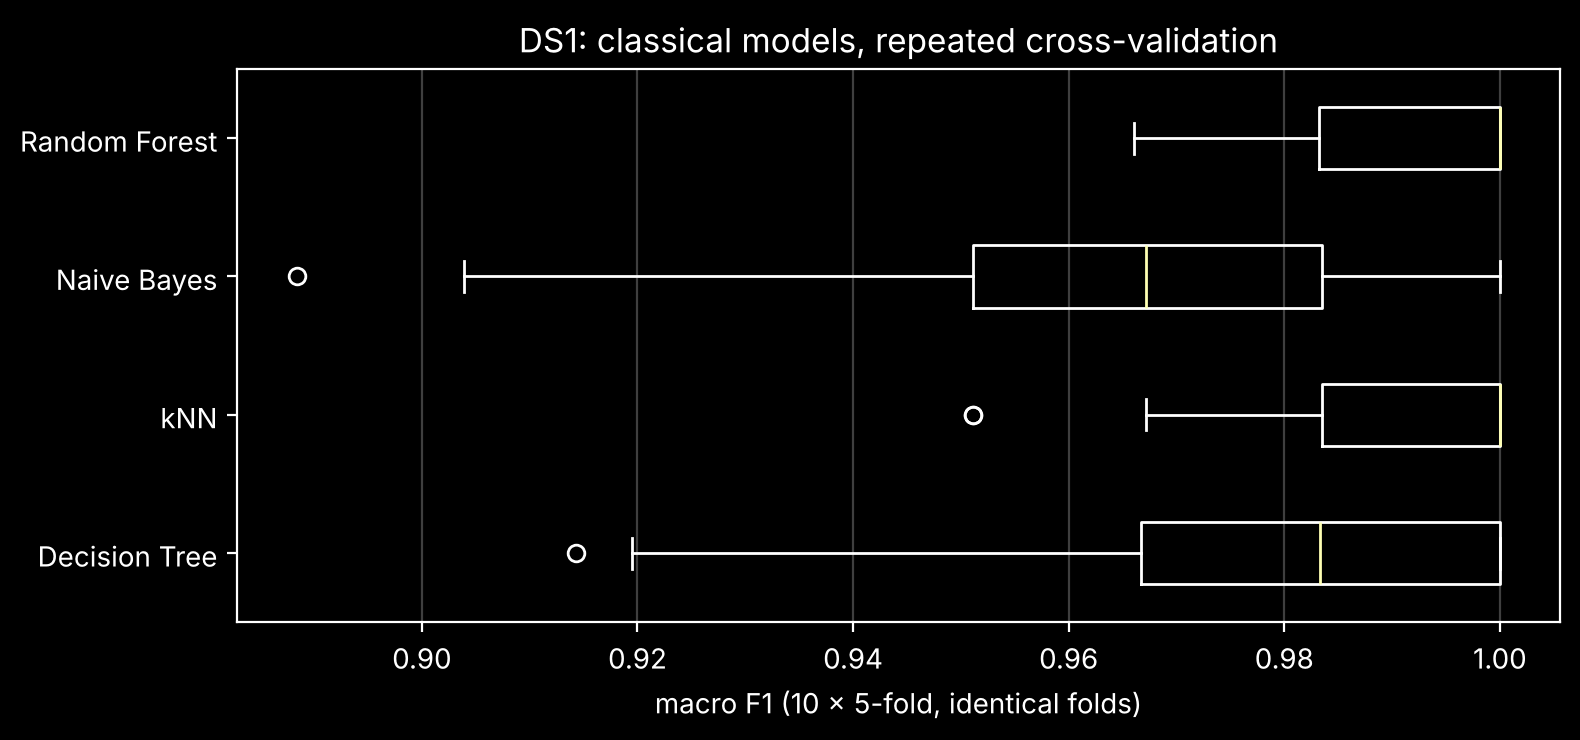

In [2]:
rcv = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=RANDOM_STATE)
ckd_recall = lambda est, X, y: recall_score(y, est.predict(X), pos_label=0)
cv_res = {name: cross_validate(m, X_train, y_train, cv=rcv,
                               scoring={"macro_f1": "f1_macro", "accuracy": "accuracy", "ckd_recall": ckd_recall})
          for name, m in models.items()}
cv_table = pd.DataFrame({
    name: {
        "CV macro F1": r["test_macro_f1"].mean(),
        "CV macro F1 std": r["test_macro_f1"].std(),
        "CV accuracy": r["test_accuracy"].mean(),
        "CV CKD recall": r["test_ckd_recall"].mean(),
        "fit time (ms)": 1000 * r["fit_time"].mean(),
    } for name, r in cv_res.items()
}).T
print(cv_table.round(3).to_string())

plt.style.use("dark_background")
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.boxplot([cv_res[n]["test_macro_f1"] for n in models], orientation="horizontal")
ax.set_yticks(range(1, len(models) + 1), list(models))
ax.set_xlabel("macro F1 (10 x 5-fold, identical folds)")
ax.set_title("DS1: classical models, repeated cross-validation")
ax.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()

**Observation:**
- kNN and Random Forest tie at the top (macro F1 0.993, std 0.012 and 0.011), followed by Decision Tree (0.979) and Naive Bayes (0.966)
- Random Forest catches every CKD patient across all 50 folds (CKD recall 1.000); Naive Bayes misses the most (0.958)
- These scores reproduce those in each model's own notebook (kNN 0.993, Decision Tree 0.979, Naive Bayes 0.966), confirming the settings were transferred correctly
- Random Forest takes about 100 times longer to fit (about 370 ms against 3 to 4 ms), which is negligible at 320 patients but grows with data size

## 2. Test set

Each model is fitted on all 320 training patients and evaluated once on the 80 test patients.

               accuracy  macro F1  ROC AUC  CKD missed  false alarms
model                                                               
Decision Tree    0.9625    0.9591    0.954           0             3
kNN              1.0000    1.0000    1.000           0             0
Naive Bayes      0.9375    0.9329    0.982           2             3
Random Forest    0.9875    0.9866    1.000           0             1


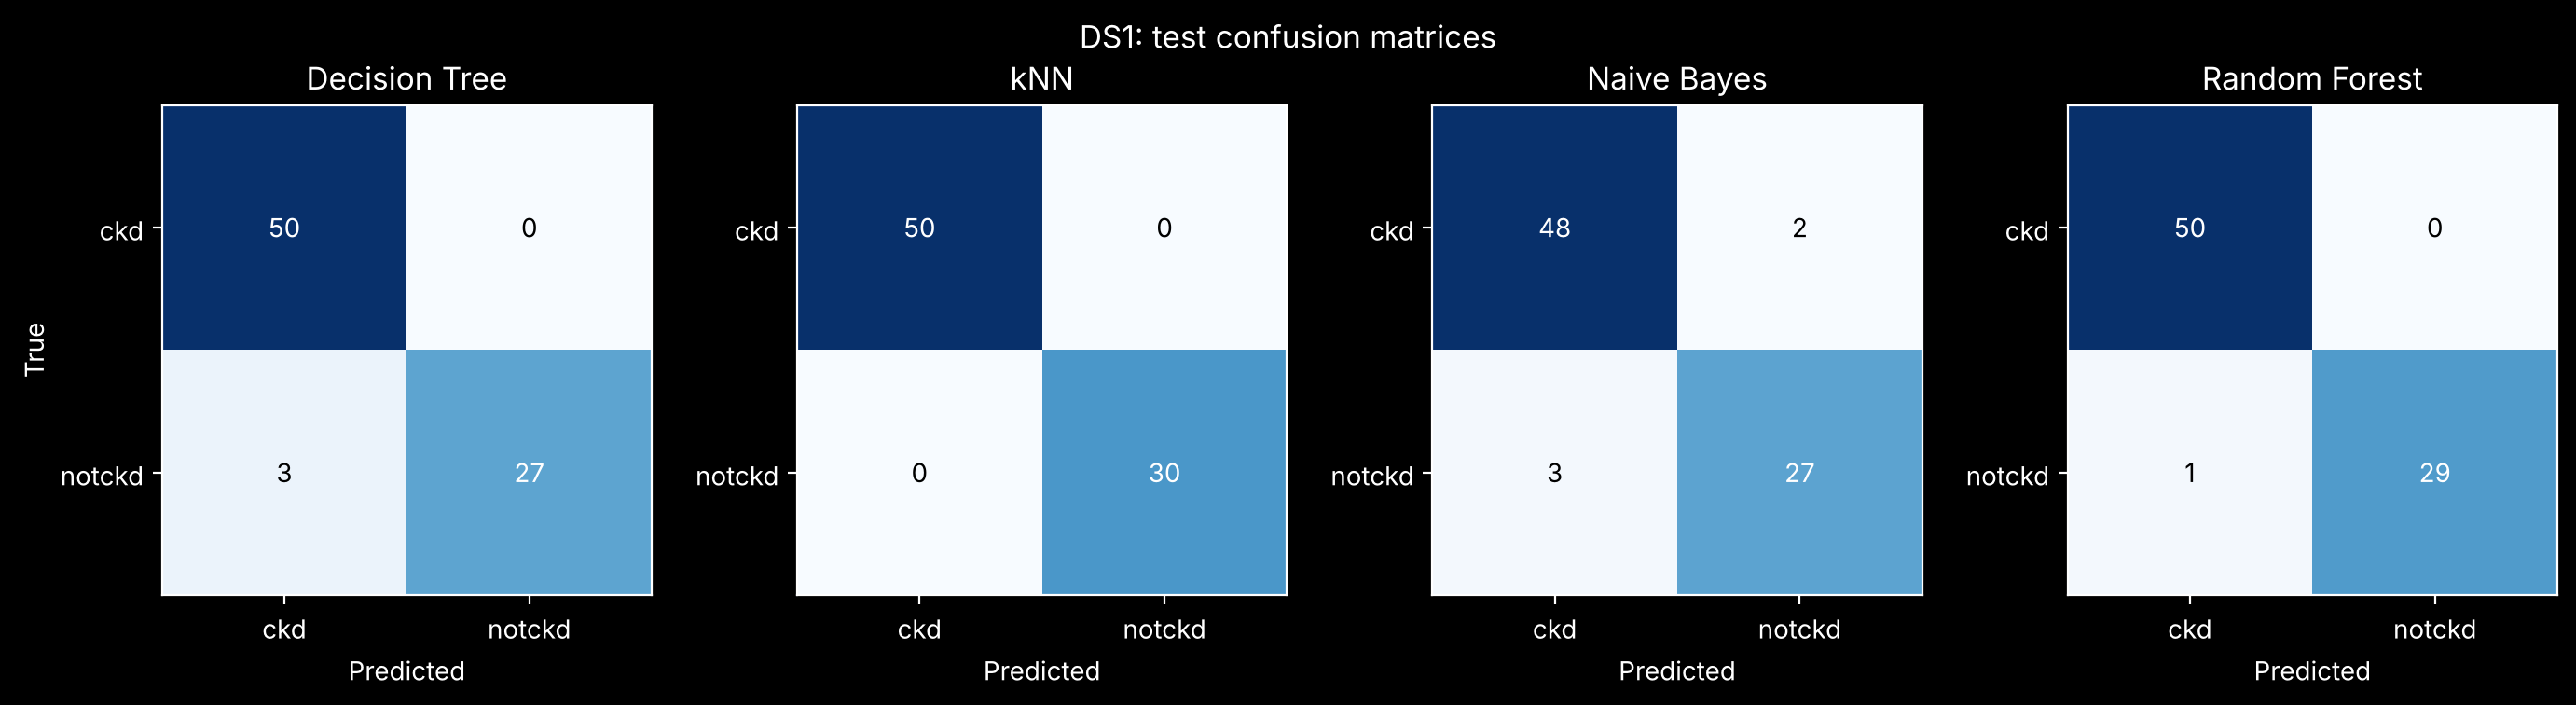

In [3]:
rows, cms = [], {}
for name, m in models.items():
    m.fit(X_train, y_train)
    pred = m.predict(X_test)
    cm = confusion_matrix(y_test, pred)
    cms[name] = cm
    rows.append({
        "model": name,
        "accuracy": accuracy_score(y_test, pred),
        "macro F1": f1_score(y_test, pred, average="macro"),
        "ROC AUC": roc_auc_score(y_test == 0, m.predict_proba(X_test)[:, 0]),
        "CKD missed": int(cm[0, 1]),
        "false alarms": int(cm[1, 0]),
    })
test_table = pd.DataFrame(rows).set_index("model")
print(test_table.round(4).to_string())

plt.style.use("dark_background")
fig, axes = plt.subplots(1, 4, figsize=(14, 3.6))
for ax, (name, cm) in zip(axes, cms.items()):
    ax.imshow(cm, cmap="Blues")
    for i in range(2):
        for j in range(2):
            ax.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "black")
    ax.set_xticks([0, 1], class_order)
    ax.set_yticks([0, 1], class_order)
    ax.set_xlabel("Predicted")
    ax.set_title(name)
axes[0].set_ylabel("True")
fig.suptitle("DS1: test confusion matrices")
plt.tight_layout()
plt.show()

**Observation:**
- kNN classifies all 80 test patients correctly; Random Forest makes 1 false alarm (macro F1 0.987); Decision Tree makes 3 false alarms (0.959); Naive Bayes misses 2 CKD patients and makes 3 false alarms (0.933)
- Only Naive Bayes misses CKD cases on the test set, matching its lowest CKD recall in cross-validation
- The test ranking agrees with cross-validation. One error is worth 0.0125 accuracy, so the gaps between kNN and Random Forest (1 patient) are too small to separate them; the gap to Naive Bayes (5 patients) is consistent across both evaluations

## 3. Conclusion and practical use

| Model | Repeated CV macro F1 | Test macro F1 | Strength for CKD screening | Weakness on DS1 |
|---|---|---|---|---|
| kNN | 0.993 | 1.000 | Highest accuracy; no training step, new patients added instantly | Needs feature selection and scaled inputs; every prediction searches all stored patients; harder to explain |
| Random Forest | 0.993 | 0.987 | Never missed a CKD case in cross-validation; feature importances | Slowest to fit; 300 trees are not readable as a rule |
| Decision Tree | 0.979 | 0.959 | 3-question rule (hemoglobin, specific gravity, albumin) a clinician can apply and audit | Coarse, over-confident probabilities; unstable splits |
| Naive Bayes | 0.966 | 0.933 | Fastest and simplest; needs only 3 routine tests; can predict with missing values | Independence assumption broken by engineered features; only model to miss CKD cases on test |

- **Best accuracy:** kNN and Random Forest are statistically tied; Random Forest's perfect CKD recall in cross-validation makes it the safer choice when a missed case is costly
- **Best explainability:** the decision tree gives most of the accuracy (0.979) with a rule a clinician can read, a useful trade-off where the reason for a referral must be shown
- **Caveat for all four:** DS1 has only 400 patients from one source, and the classes separate easily on hemoglobin and specific gravity, so these scores are likely higher than on a broader clinical population; external validation would be needed before any real use